In [1]:
import pandas as pd
import seaborn as sns
import os
import glob
import numpy as np

import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)


In [13]:
# files = glob.glob("/data/RPC_CHM13/ROB/GM*/prediction/GM*Winnowmap2.predict.out")
files = glob.glob(f"/home/jhu/jkim789/*/*.predict.out")
# files = glob.glob("/vf/users/Phillippy/projects/pooch_snakemake/test/washu-pedigree/cmd*/prediction/PAN027_PACBIO_Winnowmap2.predict.out")
# files = glob.glob("/vf/users/RPC_CHM13/ROB/test/aws/*/prediction/cmd*.predict.out")


df = pd.DataFrame()
for f in files:
    print(f)
    chrom = f.split("/")[-1].split(".")[0]
    df_sub = pd.read_csv(f, sep="\t", header = 0)
    # df_sub['sample'] = f.split("/")[4]
    # df_sub['sample'] = f.split("/")[-1].split("_")[0]
    # df_sub['sample'] = f.split("/")[-3]
    df_sub['Chrom'] = chrom
    df= pd.concat([df, df_sub], axis=0, ignore_index=True)

df = df.loc[df['Chrom'] != "chrX"]

rob_x = pd.read_csv("/path/to/project/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46_xist_slope_adjust/rob/chrX.predictions.tsv", sep ='\t' , header = 0 )
rob_x['Chrom'] = "chrX"
rob_x['Sample'] = rob_x['Sample'] + "_ONT_Winnowmap2"
rob_x

washu = pd.read_csv("/path/to/project/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46_xist_slope_adjust/washu/chrX.predictions.tsv", sep ='\t' , header = 0 )
washu['Chrom'] = "chrX"
washu

df = pd.concat([df, rob_x])
df = pd.concat([df, washu])


df['sample']  = df['Sample'].str.replace(r'(_Winnowmap2)', '', regex=True)
# df['sample']  = df['sample'].str.replace(r'(_PACBIO_Winnowmap2)', '', regex=True)
df['platform'] = "ONT"
df.loc[df['sample'].str.contains("PACBIO"), "platform"] = "HiFi"

df['Dataset']="Washu"
df.loc[df['sample'].str.contains("kolf"), 'Dataset']= "KOLF"
df.loc[df['sample'].str.contains("GM"), 'Dataset']= "ROB"

df['celltype'] = "LCL"
df.loc[df['sample'].str.contains("kolf"), 'celltype'] = "Brain"
df.loc[df['sample'].str.contains("PACBIO"), 'celltype'] = "PBMC"


cell_line_order = [  
 'PAN010_PACBIO', 'PAN011_PACBIO','PAN027_PACBIO', 'PAN028_PACBIO' ,
'PAN010_ONT','PAN011_ONT', 'PAN027_ONT', 'PAN028_ONT',
 'kolf_ipcs', 'kolf_astro', 'kolf_mgl','kolf_neuron', 'kolf_ngn2', 
 'GM03417_ONT',   'GM03786_ONT',   'GM04890_ONT',   'GM14505_ONT',]

df['Chrom'] = pd.Categorical(df['Chrom'], categories=[f'chr{i}' for i in range(1, 23)] + ['chrX'], ordered=True)

df['sample'] = pd.Categorical(df['sample'], categories=cell_line_order, ordered=True)
df = df.loc[df['sample'] != "GM14505_ONT"]
df = df.sort_values('sample')
df.head(2)

/home/jhu/jkim789/rob/chr9.predict.out
/home/jhu/jkim789/rob/chr4.predict.out
/home/jhu/jkim789/rob/chrX.predict.out
/home/jhu/jkim789/rob/chr22.predict.out
/home/jhu/jkim789/rob/chr1.predict.out
/home/jhu/jkim789/rob/chr3.predict.out
/home/jhu/jkim789/rob/chr21.predict.out
/home/jhu/jkim789/rob/chr17.predict.out
/home/jhu/jkim789/rob/chr11.predict.out
/home/jhu/jkim789/rob/chr8.predict.out
/home/jhu/jkim789/rob/chr20.predict.out
/home/jhu/jkim789/rob/chr16.predict.out
/home/jhu/jkim789/rob/chr15.predict.out
/home/jhu/jkim789/rob/chr19.predict.out
/home/jhu/jkim789/rob/chr14.predict.out
/home/jhu/jkim789/rob/chr6.predict.out
/home/jhu/jkim789/rob/chr7.predict.out
/home/jhu/jkim789/rob/chr12.predict.out
/home/jhu/jkim789/rob/chr13.predict.out
/home/jhu/jkim789/rob/chr10.predict.out
/home/jhu/jkim789/rob/chr18.predict.out
/home/jhu/jkim789/rob/chr2.predict.out
/home/jhu/jkim789/rob/chr5.predict.out
/home/jhu/jkim789/washu/chr20.predict.out
/home/jhu/jkim789/washu/chr13.predict.out
/home/

,Sample,LeftOpHapLabel,RightOpHapLabel,LeftHapPredictedOrigin,RightHapPredictedOrigin,PredictProb_Maternal-Paternal,PredictProb_Paternal-Maternal,PredictionCorrect,Chrom,XIST_diff,sample,platform,Dataset,celltype
219,PAN010_PACBIO_Winnowmap2,Hap1,Hap2,Maternal,Paternal,0.999826,0.000174,Unknown,chr22,NaN,PAN010_PACBIO,HiFi,Washu,PBMC
91,PAN010_PACBIO_Winnowmap2,Hap1,Hap2,Maternal,Paternal,0.999992,0.000008,Unknown,chr20,NaN,PAN010_PACBIO,HiFi,Washu,PBMC


In [14]:
# groupby chrom, sample, and then assign main haplotype based on number of rows that have > 0 
df['Maternal_prop'] = df['PredictProb_Maternal-Paternal']

# for Rob
df.loc[(df['Dataset'] == "ROB") & (df['Maternal_prop'] < 0.5), 'Maternal_prop'] = df.loc[(df['Dataset'] == "ROB") & (df['Maternal_prop'] < 0.5), 'PredictProb_Paternal-Maternal']

# pick haplotype assignment for kolf
df_grouped_kolf = df.loc[df['Dataset'] == "KOLF"].groupby(['Chrom']).agg({"PredictProb_Maternal-Paternal": lambda x: (x > 0.5).sum()}).reset_index().rename(columns={"PredictProb_Maternal-Paternal": "Maternal_count"})
chr_flip_kolf = df_grouped_kolf[df_grouped_kolf['Maternal_count'] < 2.5]['Chrom'].values

df.loc[(df['Chrom'].isin(chr_flip_kolf)) & (df['Dataset'] == "KOLF"), 'Maternal_prop'] = df.loc[(df['Chrom'].isin(chr_flip_kolf)) & (df['Dataset'] == "KOLF"), 'PredictProb_Paternal-Maternal']

In [15]:
df['sample'].unique()

['PAN010_PACBIO', 'PAN011_PACBIO', 'PAN027_PACBIO', 'PAN028_PACBIO', 'PAN010_ONT', ..., 'kolf_neuron', 'kolf_ngn2', 'GM03417_ONT', 'GM03786_ONT', 'GM04890_ONT']
Length: 16
Categories (17, str): ['PAN010_PACBIO' < 'PAN011_PACBIO' < 'PAN027_PACBIO' < 'PAN028_PACBIO' ... 'GM03417_ONT' < 'GM03786_ONT' < 'GM04890_ONT' < 'GM14505_ONT']

In [16]:
# Build a wide matrix robustly even when (sample, Chrom) pairs are duplicated.
# Reset index to avoid ambiguity when 'sample' is also set as index name in prior runs.
df_local = df.reset_index(drop=True).copy()

dup_mask = df_local.duplicated(subset=['sample', 'Chrom'], keep=False)
if dup_mask.any():
    print(f"Found {dup_mask.sum()} duplicated rows across sample+Chrom; using mean aggregation.")

df_wide = df_local.pivot_table(
    index='sample',
    columns='Chrom',
    values='Maternal_prop',
    aggfunc='mean'
).sort_index()

# Optional if chrY should always be shown:
# df_wide['chrY'] = 0
# df_wide = df_wide[cell_line_order]
df_wide

Chrom,chr1,chr2,chr3,chr4,chr5,chr6,chr7,chr8,chr9,chr10,...,chr14,chr15,chr16,chr17,chr18,chr19,chr20,chr21,chr22,chrX
sample,,,,,,,,,,,,,,,,,,,,,
PAN010_PACBIO,0.710321,0.999864,0.996474,0.999743,0.999186,0.999991,0.999993,0.999965,0.999702,0.995777,...,0.999999,0.999699,0.995718,0.996642,0.999998,0.999989,0.999992,0.994104,0.999826,0.999996
PAN011_PACBIO,0.999757,0.999975,0.997900,0.999185,0.997412,0.999952,0.999996,0.999976,0.999148,0.992419,...,0.999997,0.999784,0.997767,0.053629,0.999992,0.999992,0.999990,0.999894,0.999865,NaN
PAN027_PACBIO,0.999944,0.999978,0.999921,0.999273,0.999899,0.999984,0.999995,0.999944,0.999987,0.991369,...,0.999997,0.999787,0.996126,0.998088,0.999999,0.999988,0.999992,0.999913,0.999862,0.999987
PAN028_PACBIO,0.999970,0.999968,0.952413,0.999591,0.999855,0.999984,0.999995,0.999978,0.999978,0.987169,...,0.999998,0.999711,0.995538,0.996616,0.999978,0.999983,0.999993,0.999597,0.999914,0.999999
PAN010_ONT,0.999228,0.999926,0.985752,0.996532,0.990098,0.999958,0.999931,0.999774,0.192681,0.928707,...,0.999902,0.999962,0.995908,0.719314,0.999984,0.999972,0.999990,0.999990,0.999600,0.957586
PAN011_ONT,0.999041,0.999857,0.997298,0.997889,0.999324,0.999894,0.999934,0.999935,0.994402,0.981651,...,0.999915,0.999907,0.996573,0.014127,0.999974,0.999962,0.999975,0.999993,0.999439,NaN
PAN027_ONT,0.999401,0.999951,0.908130,0.996601,0.999942,0.999978,0.999977,0.999964,0.999980,0.948711,...,0.999962,0.999980,0.997350,0.999710,0.999995,0.999976,0.999989,0.999932,0.999781,0.683287
PAN028_ONT,0.999900,0.999880,0.998715,0.998715,0.997757,0.999957,0.999989,0.999978,0.999766,0.992282,...,0.999947,0.999925,0.997766,0.998936,0.999888,0.999937,0.999989,0.997089,0.999568,0.995079
kolf_ipcs,0.920755,0.654801,0.420179,0.991624,0.510554,0.999729,0.999993,0.994447,0.999599,0.986022,...,0.699465,0.999799,0.866042,0.510891,0.568332,0.995685,0.999697,0.500751,0.998392,NaN


Number of samples: 16
Annotation shape: (16, 3)
Dataset categories: ['Washu', 'KOLF', 'ROB']
Platform categories: ['PacBio', 'ONT']
Cell type categories: ['PBMC', 'LCL', 'Brain']
Heatmap shape: (23, 16)


/tmp/ipykernel_3654661/3005951353.py:112: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  platform_values = pd.Categorical(


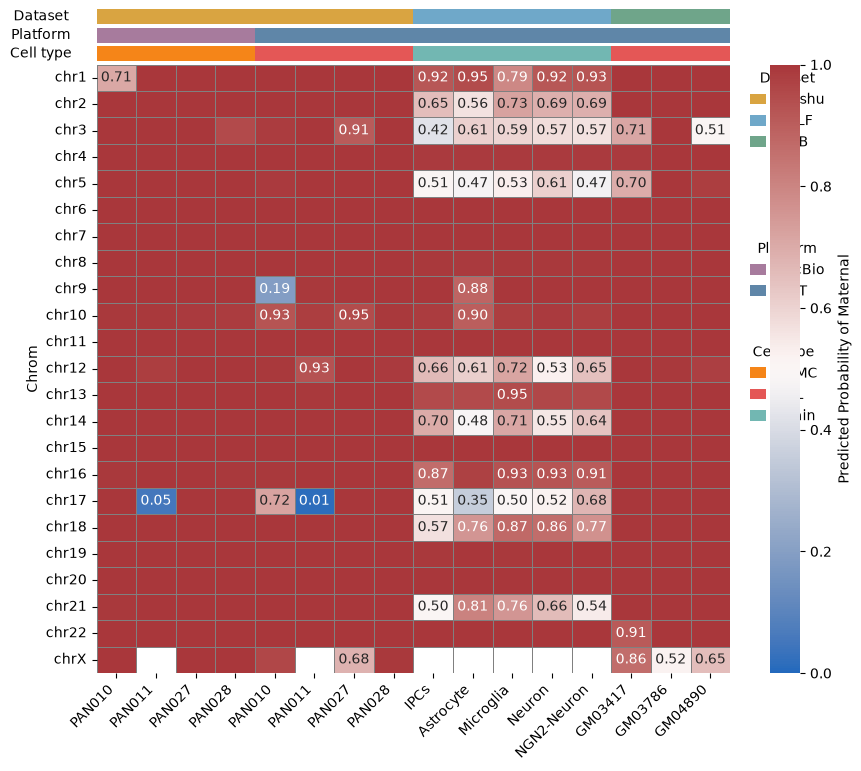

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


# ============================================================
# 1. Prepare sample order and annotation
# ============================================================

samples = df_wide.index

df_annotation = (
    df[['sample', 'Dataset', 'platform', 'celltype']]
    .drop_duplicates('sample')
    .set_index('sample')
    .loc[samples]
)

print("Number of samples:", len(samples))
print("Annotation shape:", df_annotation.shape)

dataset = df_annotation['Dataset']
platform = df_annotation['platform']
celltype = df_annotation['celltype']


# ============================================================
# 2. Define category order
# ============================================================

dataset_categories = ['Washu', 'KOLF', 'ROB']

platform_categories = ['PacBio', 'ONT']

celltype_categories = list(
    df_annotation['celltype'].dropna().unique()
)

print("Dataset categories:", dataset_categories)
print("Platform categories:", platform_categories)
print("Cell type categories:", celltype_categories)


# ============================================================
# 3. Define color palettes
# ============================================================

dataset_colors = [
    '#D9A441',  # Washu
    '#6FA8C9',  # KOLF
    '#6FA58A',  # ROB
]

platform_colors = [
    '#A77B9D',  # PacBio
    '#5F86A8',  # ONT
]

celltype_colors = [
    '#F58518',
    '#E45756',
    '#72B7B2',
    '#B279A2',
    '#FF9DA6',
    '#9D755D',
]


# Check number of colors
if len(dataset_categories) > len(dataset_colors):
    raise ValueError("Not enough Dataset colors.")

if len(platform_categories) > len(platform_colors):
    raise ValueError("Not enough Platform colors.")

if len(celltype_categories) > len(celltype_colors):
    raise ValueError(
        f"Not enough cell type colors: "
        f"{len(celltype_categories)} categories but "
        f"{len(celltype_colors)} colors."
    )


# Create colormaps
dataset_cmap = ListedColormap(
    dataset_colors[:len(dataset_categories)]
)

platform_cmap = ListedColormap(
    platform_colors[:len(platform_categories)]
)

celltype_cmap = ListedColormap(
    celltype_colors[:len(celltype_categories)]
)


# ============================================================
# 4. Convert categories to numeric codes
# ============================================================

dataset_values = pd.Categorical(
    dataset,
    categories=dataset_categories,
    ordered=True
).codes

platform_values = pd.Categorical(
    platform,
    categories=platform_categories,
    ordered=True
).codes

celltype_values = pd.Categorical(
    celltype,
    categories=celltype_categories,
    ordered=True
).codes


# ============================================================
# 5. Create annotation matrices
# ============================================================

dataset_matrix = pd.DataFrame(
    [dataset_values],
    index=['Dataset'],
    columns=samples
)

platform_matrix = pd.DataFrame(
    [platform_values],
    index=['Platform'],
    columns=samples
)

celltype_matrix = pd.DataFrame(
    [celltype_values],
    index=['Cell type'],
    columns=samples
)


# ============================================================
# 6. Prepare heatmap
# ============================================================

heatmap_data = df_wide.T.copy()
heatmap_data = heatmap_data.clip(0, 1)
# heatmap_data

dataset_matrix = dataset_matrix[heatmap_data.columns]
platform_matrix = platform_matrix[heatmap_data.columns]
celltype_matrix = celltype_matrix[heatmap_data.columns]

print("Heatmap shape:", heatmap_data.shape)

# Annotate ambiguous calls (0.4-0.6) with the value, missing data as "NA", else blank
annot_matrix = heatmap_data.map(
    lambda v: "NA" if pd.isna(v) else (f"{v:.2f}" if v < 0.95 else "")
    # lambda v: "NA" if pd.isna(v) else f"{v:.2f}"
)


# ============================================================
# 7. Create figure
# ============================================================

fig = plt.figure(figsize=(12, 8))

gs = fig.add_gridspec(
    nrows=4,
    ncols=1,
    height_ratios=[0.15, 0.15, 0.15, 6],
    hspace=0.02
)

ax_dataset = fig.add_subplot(gs[0])
ax_platform = fig.add_subplot(gs[1])
ax_celltype = fig.add_subplot(gs[2])
ax_heatmap = fig.add_subplot(gs[3])


# ============================================================
# 8. Dataset annotation
# ============================================================

dataset_norm = BoundaryNorm(
    np.arange(len(dataset_categories) + 1) - 0.5,
    len(dataset_categories)
)

sns.heatmap(
    dataset_matrix,
    cmap=dataset_cmap,
    norm=dataset_norm,
    cbar=False,
    xticklabels=False,
    yticklabels=False,
    linewidths=0,
    ax=ax_dataset
)

ax_dataset.set_ylabel(
    'Dataset',
    rotation=0,
    labelpad=40,
    va='center'
)


# ============================================================
# 9. Platform annotation
# ============================================================

platform_norm = BoundaryNorm(
    np.arange(len(platform_categories) + 1) - 0.5,
    len(platform_categories)
)

sns.heatmap(
    platform_matrix,
    cmap=platform_cmap,
    norm=platform_norm,
    cbar=False,
    xticklabels=False,
    yticklabels=False,
    linewidths=0,
    ax=ax_platform
)

ax_platform.set_ylabel(
    'Platform',
    rotation=0,
    labelpad=40,
    va='center'
)


# ============================================================
# 10. Cell type annotation
# ============================================================

celltype_norm = BoundaryNorm(
    np.arange(len(celltype_categories) + 1) - 0.5,
    len(celltype_categories)
)

sns.heatmap(
    celltype_matrix,
    cmap=celltype_cmap,
    norm=celltype_norm,
    cbar=False,
    xticklabels=False,
    yticklabels=False,
    linewidths=0,
    ax=ax_celltype
)

ax_celltype.set_ylabel(
    'Cell type',
    rotation=0,
    labelpad=40,
    va='center'
)


# ============================================================
# 11. Main heatmap
# ============================================================

sns.heatmap(
    heatmap_data,
    cmap='vlag',
    vmin=0,
    vmax=1,
    center=0.5,
    annot=annot_matrix,
    fmt='',
    cbar_kws={
        'label': 'Predicted Probability of Maternal'
    },
    linewidths=0.5,
    linecolor='gray',

    ax=ax_heatmap
)

ax_heatmap.set_xticklabels(
    ax_heatmap.get_xticklabels(),
    rotation=45,
    ha='right'
)

# Map sample names to display labels for the x-axis; edit this dict to rename any sample
x_axis_labels = {s: s for s in heatmap_data.columns}
x_axis_labels = {'PAN010_PACBIO' : "PAN010",
                 'PAN011_PACBIO' : "PAN011",
                 'PAN027_PACBIO' : "PAN027",
                  'PAN028_PACBIO' : "PAN028",
                  'PAN010_ONT' : "PAN010",
                  'PAN011_ONT' : "PAN011",
                  'PAN027_ONT' : "PAN027",
                  'PAN028_ONT' : "PAN028",
                  'kolf_ipcs' : "IPCs",
                  'kolf_astro' : "Astrocyte",
                  'kolf_mgl' : "Microglia",
                  'kolf_neuron' : "Neuron",
                  'kolf_ngn2' : "NGN2-Neuron",
                  'GM03417_ONT' : "GM03417",
                  'GM03786_ONT' : "GM03786",
                  'GM04890_ONT' : "GM04890",
                  'GM14505_ONT' : "GM14505"}
ax_heatmap.set_xticklabels(
    [x_axis_labels.get(t.get_text(), t.get_text()) for t in ax_heatmap.get_xticklabels()],
    rotation=45,
    ha='right'
)

ax_heatmap.set_yticklabels(
    ax_heatmap.get_yticklabels(),
    rotation=0
)


# ============================================================
# 12. Clean up
# ============================================================

for ax in [ax_dataset, ax_platform, ax_celltype]:
    ax.set_xlabel('')

ax_heatmap.set_xlabel('')

sns.despine(
    ax=ax_dataset,
    left=True,
    bottom=True
)

sns.despine(
    ax=ax_platform,
    left=True,
    bottom=True
)

sns.despine(
    ax=ax_celltype,
    left=True,
    bottom=True
)


# ============================================================
# 13. Create legend handles
# ============================================================

dataset_legend = [
    Patch(
        facecolor=dataset_colors[i],
        edgecolor='none',
        label=category
    )
    for i, category in enumerate(dataset_categories)
]

platform_legend = [
    Patch(
        facecolor=platform_colors[i],
        edgecolor='none',
        label=category
    )
    for i, category in enumerate(platform_categories)
]

celltype_legend = [
    Patch(
        facecolor=celltype_colors[i],
        edgecolor='none',
        label=category
    )
    for i, category in enumerate(celltype_categories)
]


# ============================================================
# 14. Add legends
# ============================================================

legend1 = ax_heatmap.legend(
    handles=dataset_legend,
    title='Dataset',
    loc='upper left',
    bbox_to_anchor=(1.02, 1.00),
    frameon=False,
    handlelength=1.2,
    handleheight=0.8,
    labelspacing=0.5,
    borderpad=0.0
)

ax_heatmap.add_artist(legend1)


legend2 = ax_heatmap.legend(
    handles=platform_legend,
    title='Platform',
    loc='upper left',
    bbox_to_anchor=(1.02, 0.72),
    frameon=False,
    handlelength=1.2,
    handleheight=0.8,
    labelspacing=0.5,
    borderpad=0.0
)

ax_heatmap.add_artist(legend2)


legend3 = ax_heatmap.legend(
    handles=celltype_legend,
    title='Cell type',
    loc='upper left',
    bbox_to_anchor=(1.02, 0.55),
    frameon=False,
    handlelength=1.2,
    handleheight=0.8,
    labelspacing=0.5,
    borderpad=0.0
)


# ============================================================
# 15. Make room for legends
# ============================================================

plt.subplots_adjust(
    right=0.78,
    left=0.12,
    top=0.95,
    bottom=0.12
)

# The heatmap's colorbar narrows ax_heatmap; match the annotation strips to its new width
heatmap_pos = ax_heatmap.get_position()
for ax in [ax_dataset, ax_platform, ax_celltype]:
    ax_pos = ax.get_position()
    ax.set_position([heatmap_pos.x0, ax_pos.y0, heatmap_pos.width, ax_pos.height])


plt.savefig('/home/jhu/jkim789/projects_aphill27/projects/pooch/figures/wahsu_rob_heatmap_with_legends.pdf')
plt.show()

In [ ]:
pair = {'GM03786_ONT' : ['chr14','chr13'],
        'GM04890_ONT' : ['chr13','chr14'],
        'GM03417_ONT' : ['chr21', 'chr14'],  
        # 'GM14505_ONT' : ['chrY', 'chr13']     # Excluded: chrY not in data
        }
pair

{'GM03786_ONT': ['chr14', 'chr13'],
 'GM04890_ONT': ['chr13', 'chr14'],
 'GM03417_ONT': ['chr21', 'chr14'],
 'GM14505_ONT': ['chrY', 'chr13']}

In [28]:
records = []
for sample, (chr1, chr2) in pair.items():
    if sample not in df_wide.index:
        print(f"Sample {sample} not found in df_wide index; skipping.")
        continue
    if chr1 not in df_wide.columns or chr2 not in df_wide.columns:
        
        continue

    print(f"Processing sample: {sample}, chromosomes: {chr1}, {chr2}")
    left_val = float(df_wide.loc[sample, chr1])
    right_val = float(df_wide.loc[sample, chr2])
    records.append({
        'sample': str(sample),
        'left_chr': chr1,
        'right_chr': chr2,
        'left': left_val,
        'right': right_val,
    })

main_df = pd.DataFrame(records)
main_df

Processing sample: GM03786_ONT, chromosomes: chr14, chr13
Processing sample: GM04890_ONT, chromosomes: chr13, chr14
Processing sample: GM03417_ONT, chromosomes: chr21, chr14


,sample,left_chr,right_chr,left,right
0,GM03786_ONT,chr14,chr13,0.999990,0.999829
1,GM04890_ONT,chr13,chr14,0.999315,0.999960
2,GM03417_ONT,chr21,chr14,0.999965,0.999929


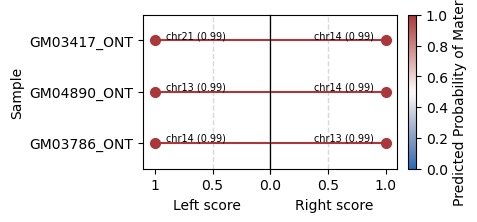

In [27]:
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import ScalarMappable

fig, axes = plt.subplots(ncols=2, sharey=True, figsize=(3.6, 2), gridspec_kw={"wspace": 0.0})

y = np.arange(len(main_df))
chr_names = main_df["sample"].astype(str).to_numpy()
left_raw = main_df["left"].astype(float).to_numpy()
right_raw = main_df["right"].astype(float).to_numpy()
left_vals = -left_raw
right_vals = right_raw

# Colormap settings requested
cmap = plt.get_cmap("vlag")
norm = TwoSlopeNorm(vmin=0, vcenter=0.5, vmax=1)

# Add top/bottom margin so first and last samples are not touching frame
ymin, ymax = -0.5, len(main_df) - 0.5

# Left panel (mirrored): data range is -1 to 0, but display tick labels as 0 to 1
for i in range(len(y)):
    color_left = cmap(norm(left_raw[i]))
    axes[0].hlines(y=y[i], xmin=left_vals[i], xmax=0, color=color_left)
    axes[0].plot(left_vals[i], y[i], "o", color=color_left, markersize=7)

axes[0].set_xlim(-1.1, 0)
axes[0].set_ylim(ymin, ymax)
axes[0].set_xlabel("Left score")
axes[0].set_ylabel("Sample")
axes[0].set_yticks(y.tolist())
axes[0].set_yticklabels(chr_names.tolist())
axes[0].axvline(x=-0.5, color="gray", linewidth=1, zorder=-100, alpha=0.3, linestyle="--")
axes[0].axvline(0, color="gray", linewidth=1)
axes[0].set_xticks([-1, -0.5, 0])
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, pos: "" if np.isclose(x, 0) else f"{-x:g}"))

# Right panel: 0 to 1
for i in range(len(y)):
    color_right = cmap(norm(right_raw[i]))
    axes[1].hlines(y=y[i], xmin=0, xmax=right_vals[i], color=color_right)
    axes[1].plot(right_vals[i], y[i], "o", color=color_right, markersize=7)

axes[1].set_xlim(0, 1.1)
axes[1].axvline(x=0.5, color="gray", linewidth=1, zorder=-100, alpha=0.3, linestyle="--")
axes[1].set_ylim(ymin, ymax)
axes[1].set_xlabel("Right score")
axes[1].axvline(0, color="gray", linewidth=1)
axes[1].set_xticks([0, 0.5, 1])
axes[1].tick_params(axis="y", left=False, labelleft=False)

# Fixed in-panel value labels
left_label_x = -0.9
right_label_x = 0.9

# Truncate to 2 decimal places (no rounding)
left_trunc = np.floor(left_raw * 100) / 100
right_trunc = np.floor(right_raw * 100) / 100

for i, val in enumerate(left_trunc):
    axes[0].text(left_label_x, y[i] + 0.1, f"{pair[chr_names[i]][0]} ({val:.2f})", va="center", ha="left", fontsize=7, color="black")

for i, val in enumerate(right_trunc):
    axes[1].text(right_label_x, y[i] + 0.1, f"{pair[chr_names[i]][1]} ({val:.2f})", va="center", ha="right", fontsize=7, color="black")

# Color legend
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, fraction=0.05, pad=0.04)
cbar.set_label("Predicted Probability of Maternal")

plt.savefig(os.path.join(figureDir, "ROB_prediction_mirrored.pdf"), bbox_inches='tight', dpi=300)
plt.show()